In [2]:
import pandas as pd

# Cargar el archivo
df = pd.read_csv('SECTORES_CRITICOS_POR_EXCESO_DE_VELOCIDAD_20261118.csv')

print(f"Filas: {df.shape[0]} | Columnas: {df.shape[1]}")
print("\n--- Información de Columnas ---")
print(df.info())

display(df.head())


Filas: 970 | Columnas: 12

--- Información de Columnas ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 970 entries, 0 to 969
Data columns (total 12 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   ICOUNT         970 non-null    int64 
 1   ID_MT          615 non-null    object
 2   ENTIDAD        970 non-null    object
 3   ID_TRAMO       749 non-null    object
 4   TIPO_CALZ      749 non-null    object
 5   PR             970 non-null    object
 6   Latitud        970 non-null    object
 7   Longitud       970 non-null    object
 8   Clasificacion  970 non-null    object
 9   Municipio      970 non-null    object
 10  Departamento   970 non-null    object
 11  divipola       970 non-null    int64 
dtypes: int64(2), object(10)
memory usage: 91.1+ KB
None


,ICOUNT,ID_MT,ENTIDAD,ID_TRAMO,TIPO_CALZ,PR,Latitud,Longitud,Clasificacion,Municipio,Departamento,divipola
0,2,NaN,INVIAS-OTROS,NaN,NaN,37,"1,020441","-77,698917",Muy Bajo,SAPUYES,NARIÑO,52720
1,2,4G025,ANI,RumPast_Tramo_UF3,Doble,36,"0,997095","-77,474728",Muy Bajo,ILES,NARIÑO,52352
2,4,4G025,ANI,RumPast_Tramo_UF5,Doble,79,"1,163092","-77,286501",Muy Bajo,PASTO,NARIÑO,52001
3,2,NaN,INVIAS-OTROS,RPC_Tramo_5VOrientPasto,Sencilla,sd,"1,168242","-77,255688",Muy Bajo,PASTO,NARIÑO,52001
4,2,NaN,INVIAS-OTROS,ViaPuerto_Tramo_UF0,Sencilla,20,"3,879461","-76,922322",Muy Bajo,BUENAVENTURA,VALLE DEL CAUCA,76109


In [3]:
# ==============================================================================
# CELDA 1: LIBRERÍAS Y CONFIGURACIÓN INICIAL
# Citas de clase:
# - preparacion_datos_ML_clase.ipynb (Librerías estándar de ML)
# - Clases_3_corte.pptx (Configuración del pipeline CRISP-DM)
# ==============================================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

# Algoritmos Supervisados de Clasificación aprendidos en clase
from sklearn.linear_model import LogisticRegression         # Basado en Copy of lineal_logistica_publicidad.ipynb
from sklearn.tree import DecisionTreeClassifier             # Basado en Arboles_Clasificación_Regresión.ipynb
from sklearn.ensemble import RandomForestClassifier         # Basado en rf_paso_a_paso.ipynb
from xgboost import XGBClassifier                           # Basado en xgboost_6.ipynb y xgboost.pptx
from lightgbm import LGBMClassifier                         # Basado en LightGBM_Regresion_Hiperparametros.ipynb

# Preprocesamiento y Métricas de Evaluación
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

# Configuración visual de clase (estilo ggplot)
plt.style.use('ggplot')
plt.rcParams['figure.figsize'] = (10, 5)
RANDOM_STATE = 42

print("✅ Librerías cargadas correctamente con semilla reproducible RANDOM_STATE =", RANDOM_STATE)

✅ Librerías cargadas correctamente con semilla reproducible RANDOM_STATE = 42


In [5]:
# ==============================================================================
# CELDA 2: CARGA DEL DATASET Y CREACIÓN DE LA VARIABLE OBJETIVO
# Citas de clase:
# - Proyecto integrador.pdf / datos.gov.co (Sectores Críticos por Exceso de Velocidad)
# - EDA Exploratory Data Analysis.ipynb (Inspección inicial y transformación de tipos)
# ==============================================================================

# Se corrige el nombre del archivo con la fecha del dataset disponible
df = pd.read_csv('SECTORES_CRITICOS_POR_EXCESO_DE_VELOCIDAD_20261118.csv')

print(f"📊 Dataset cargado: {df.shape[0]} filas y {df.shape[1]} columnas.")

# 1. Limpieza de coordenadas: Convertir texto con comas ('1,0204') a tipo float numérico
df['Latitud'] = df['Latitud'].astype(str).str.replace(',', '.').astype(float)
df['Longitud'] = df['Longitud'].astype(str).str.replace(',', '.').astype(float)

# 2. Definición de la Variable Objetivo (target_riesgo):
# Basado en la técnica de binarización categórica vista en Copy of lineal_logistica_publicidad.ipynb
categorias_alto_riesgo = ['Alto', 'Muy Alto', 'ALTO', 'MUY ALTO']
df['target_riesgo'] = df['Clasificacion'].apply(lambda x: 1 if str(x).strip() in categorias_alto_riesgo else 0)

print("\n--- Distribución de Clases (Frecuencia y Porcentaje) ---")
conteo = df['target_riesgo'].value_counts()
porcentaje = df['target_riesgo'].value_counts(normalize=True).map('{:.1%}'.format)

display(pd.DataFrame({'Cantidad': conteo, 'Porcentaje': porcentaje}))

📊 Dataset cargado: 970 filas y 12 columnas.

--- Distribución de Clases (Frecuencia y Porcentaje) ---


,Cantidad,Porcentaje
target_riesgo,,
0,933,96.2%
1,37,3.8%


In [6]:
# ==============================================================================
# CELDA 3: PREPARACIÓN DE DATOS (REGLAS STRICTAS ANTI-DATA LEAKAGE)
# Citas de clase:
# - preparacion_datos_ML_clase.ipynb (Paso 5: train_test_split ANTES de imputar/escalar)
# - SegundocorteML_socialización.docx (Tratamiento de nulos y One-Hot Encoding)
# ==============================================================================

# 1. Descartar identificadores de alta cardinalidad que generarían sobreajuste
cols_descartar = ['ICOUNT', 'ID_MT', 'ID_TRAMO', 'PR', 'divipola', 'Clasificacion', 'Municipio']
df_modelo = df.drop(columns=[c for c in cols_descartar if c in df.columns])

# 2. Separar características (X) y objetivo (y)
X = df_modelo.drop(columns=['target_riesgo'])
y = df_modelo['target_riesgo']

# 3. División Train / Test (80% entrenamiento, 20% prueba)
# REGLA DE ORO DE CLASE: Dividir PRIMERO para evitar Data Leakage
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

# 4. Imputación estadística de nulos
# Numéricas -> Mediana (resistente a asimetría) | Categóricas -> Moda
cols_num = X_train.select_dtypes(include=[np.number]).columns.tolist()
cols_cat = X_train.select_dtypes(include=['object', 'category']).columns.tolist()

imputer_num = SimpleImputer(strategy='median')
X_train[cols_num] = imputer_num.fit_transform(X_train[cols_num])
X_test[cols_num] = imputer_num.transform(X_test[cols_num])

if cols_cat:
    imputer_cat = SimpleImputer(strategy='most_frequent')
    X_train[cols_cat] = imputer_cat.fit_transform(X_train[cols_cat])
    X_test[cols_cat] = imputer_cat.transform(X_test[cols_cat])

# 5. Codificación categórica (One-Hot Encoding con pd.get_dummies)
X_train = pd.get_dummies(X_train, columns=cols_cat, drop_first=True, dtype=int)
X_test = pd.get_dummies(X_test, columns=cols_cat, drop_first=True, dtype=int)

# Garantizar alineación exacta de columnas entre conjunto de train y test
X_train, X_test = X_train.align(X_test, join='left', axis=1, fill_value=0)

# 6. Escalado estadístico (StandardScaler)
# fit_transform solo en Train; transform solo en Test
scaler = StandardScaler()
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[cols_num] = scaler.fit_transform(X_train[cols_num])
X_test_scaled[cols_num] = scaler.transform(X_test[cols_num])

print("✅ Preprocesamiento sin Data Leakage completado.")
print(f"Dimensiones de X_train: {X_train.shape} | X_test: {X_test.shape}")

✅ Preprocesamiento sin Data Leakage completado.
Dimensiones de X_train: (776, 28) | X_test: (194, 28)


In [7]:
# ==============================================================================
# CELDA 4: ENTRENAMIENTO Y COMPARACIÓN DE 5 ALGORITMOS SUPERVISADOS
# Citas de clase:
# - Clases_3_corte.pptx (Mínimo 3 modelos comparados con métricas completas)
# - SegundocorteML_socialización.docx (Evaluación con Accuracy, Precision, Recall, F1)
# ==============================================================================

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

modelos = {
    'Regresión Logística': LogisticRegression(random_state=RANDOM_STATE),
    'Árbol de Decisión': DecisionTreeClassifier(max_depth=5, random_state=RANDOM_STATE),
    'Random Forest': RandomForestClassifier(n_estimators=100, max_depth=6, random_state=RANDOM_STATE),
    'XGBoost': XGBClassifier(n_estimators=100, learning_rate=0.1, max_depth=4, random_state=RANDOM_STATE),
    'LightGBM': LGBMClassifier(n_estimators=100, learning_rate=0.1, max_depth=4, random_state=RANDOM_STATE, verbose=-1)
}

tabla_resultados = []

for nombre, modelo in modelos.items():
    # Usar datos escalados para Regresión Logística y originales codificados para ensambles de árboles
    if nombre == 'Regresión Logística':
        modelo.fit(X_train_scaled, y_train)
        predicciones = modelo.predict(X_test_scaled)
    else:
        modelo.fit(X_train, y_train)
        predicciones = modelo.predict(X_test)

    # Métricas clave de clasificación vistas en clase
    acc = accuracy_score(y_test, predicciones)
    prec = precision_score(y_test, predicciones, zero_division=0)
    rec = recall_score(y_test, predicciones, zero_division=0)
    f1 = f1_score(y_test, predicciones, zero_division=0)

    tabla_resultados.append({
        'Modelo': nombre,
        'Accuracy': round(acc, 4),
        'Precision': round(prec, 4),
        'Recall': round(rec, 4),
        'F1-Score': round(f1, 4)
    })

# Convertir a DataFrame y ordenar de mejor a peor según F1-Score
df_resumen = pd.DataFrame(tabla_resultados).sort_values(by='F1-Score', ascending=False).reset_index(drop=True)

print("=== TABLA COMPARATIVA DE MODELOS (EVALUACIÓN EN TEST) ===")
display(df_resumen)

=== TABLA COMPARATIVA DE MODELOS (EVALUACIÓN EN TEST) ===


,Modelo,Accuracy,Precision,Recall,F1-Score
0,Árbol de Decisión,0.9691,0.5714,0.5714,0.5714
1,LightGBM,0.9588,0.4000,0.2857,0.3333
2,Regresión Logística,0.9639,0.0000,0.0000,0.0000
3,Random Forest,0.9536,0.0000,0.0000,0.0000
4,XGBoost,0.9536,0.0000,0.0000,0.0000


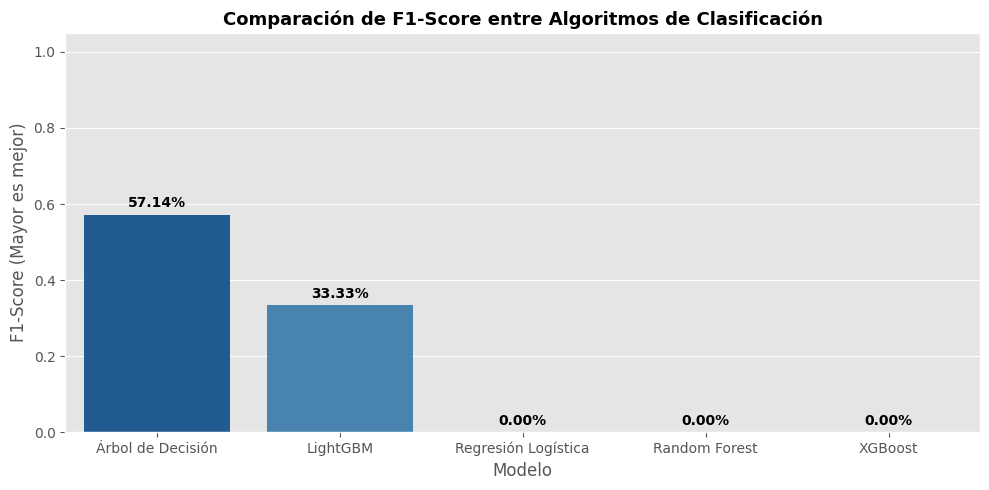

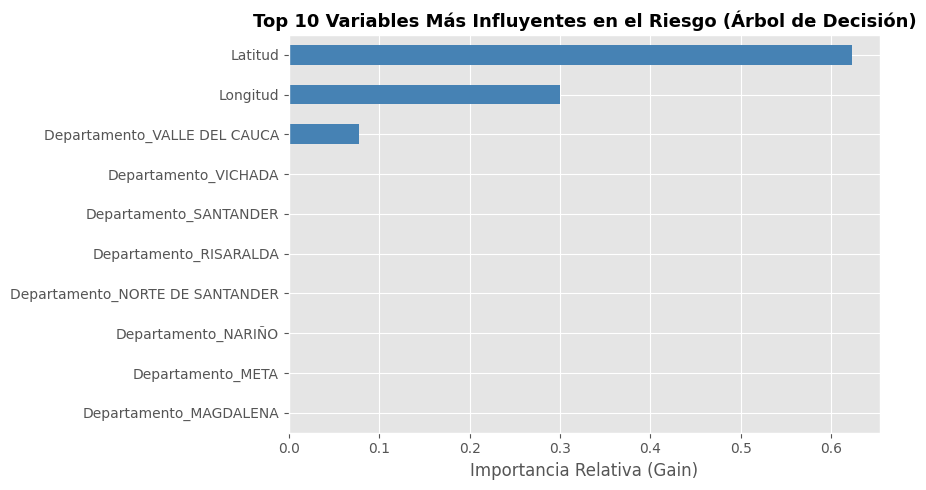

In [8]:
# ==============================================================================
# CELDA 5: GRÁFICAS DE DESEMPEÑO E IMPORTANCIA DE VARIABLES
# Citas de clase:
# - Copia_de_Taller_guiado_de_visualización_de_datos_con_Matplotlib.ipynb
# - LightGBM_Regresion_Hiperparametros_e_Importancia.ipynb (Importancia de características)
# ==============================================================================

# 1. Gráfica de Barras comparando F1-Score entre los 5 algoritmos
plt.figure(figsize=(10, 5))
ax = sns.barplot(data=df_resumen, x='Modelo', y='F1-Score', palette='Blues_r', hue='Modelo', legend=False)
plt.title('Comparación de F1-Score entre Algoritmos de Clasificación', fontsize=13, fontweight='bold')
plt.ylabel('F1-Score (Mayor es mejor)')
plt.ylim(0, 1.05)

for p in ax.patches:
    ax.annotate(
        f"{p.get_height():.2%}",
        (p.get_x() + p.get_width() / 2., p.get_height() + 0.02),
        ha='center', fontsize=10, fontweight='bold'
    )

plt.tight_layout()
plt.show()

# 2. Extraer e interpretar la Importancia de Variables del Modelo Ganador
nombre_ganador = df_resumen.iloc[0]['Modelo']          # ✅ fila 0, columna 'Modelo'
modelo_ganador = modelos[nombre_ganador]

if hasattr(modelo_ganador, 'feature_importances_'):
    importancias = (
        pd.Series(modelo_ganador.feature_importances_, index=X_train.columns)
        .sort_values(ascending=True)
        .tail(10)
    )

    plt.figure(figsize=(9, 5))
    importancias.plot(kind='barh', color='steelblue')
    plt.title(f'Top 10 Variables Más Influyentes en el Riesgo ({nombre_ganador})',
              fontsize=13, fontweight='bold')
    plt.xlabel('Importancia Relativa (Gain)')
    plt.tight_layout()
    plt.show()

elif hasattr(modelo_ganador, 'coef_'):
    # 🔧 Caso Regresión Logística: no tiene feature_importances_, usa coef_
    importancias = (
        pd.Series(np.abs(modelo_ganador.coef_[0]), index=X_train.columns)
        .sort_values(ascending=True)
        .tail(10)
    )

    plt.figure(figsize=(9, 5))
    importancias.plot(kind='barh', color='steelblue')
    plt.title(f'Top 10 Variables Más Influyentes (|Coeficiente|) — {nombre_ganador}',
              fontsize=13, fontweight='bold')
    plt.xlabel('Importancia Relativa (|Coef|)')
    plt.tight_layout()
    plt.show()

else:
    print(f"⚠️ El modelo ganador ({nombre_ganador}) no expone importancia de variables directamente.")

In [9]:
# ==============================================================================
# CELDA 6: EXPORTACIÓN DE ARCHIVOS PKL PARA STREAMLIT (FASE DE DESPLIEGUE)
# Citas de clase:
# - Clases_3_corte.pptx (Requisito 3: App interactiva en Streamlit `app.py`)
# - PruebaCienciadedatos_20262 - Resultados2.pdf (Guardado de modelo y escalador)
# ==============================================================================

# Guardar el modelo clasificador ganador
joblib.dump(modelo_ganador, 'modelo_siniestralidad_vial.pkl')

# Guardar el escalador estadístico
joblib.dump(scaler, 'escalador_vial.pkl')

# 🔧 Guardar también las columnas exactas de entrenamiento:
#     Streamlit deberá reindexar el input a este orden para que el modelo no falle.
joblib.dump(list(X_train.columns), 'columnas_train.pkl')

# 🔧 Guardar la lista de columnas numéricas escaladas (para saber qué transformar en la app)
joblib.dump(cols_num, 'cols_num.pkl')

# 🔧 Guardar el diccionario de categorías de riesgo (por si la app necesita mapear etiquetas)
joblib.dump(categorias_alto_riesgo, 'categorias_alto_riesgo.pkl')

print(f"✅ ¡Modelo ganador '{nombre_ganador}' y escalador exportados como '.pkl' exitosamente!")
print("Archivos generados:")
print("  - modelo_siniestralidad_vial.pkl")
print("  - escalador_vial.pkl")
print("  - columnas_train.pkl")
print("  - cols_num.pkl")
print("  - categorias_alto_riesgo.pkl")

✅ ¡Modelo ganador 'Árbol de Decisión' y escalador exportados como '.pkl' exitosamente!
Archivos generados:
  - modelo_siniestralidad_vial.pkl
  - escalador_vial.pkl
  - columnas_train.pkl
  - cols_num.pkl
  - categorias_alto_riesgo.pkl


**Fase de Despliegue (Exportación de Artefactos y Configuración de la App)**

In [10]:
%%writefile app.py

import streamlit as st
import pandas as pd
import numpy as np
import joblib

# Configuración de la página web
st.set_page_config(page_title="Predicción de Riesgo Vial", page_icon="🚨", layout="wide")

st.title("🚨 Clasificador de Sectores Críticos por Exceso de Velocidad")
st.subheader("Proyecto Integrador - Fundamentos de Ciencia de Datos")
st.write("Aplicación para predecir si un tramo vial en Colombia es de **Alto Riesgo** mediante Machine Learning.")

# Cargar el modelo entrenado
@st.cache_resource
def cargar_modelo():
    modelo = joblib.load('modelo_siniestralidad_vial.pkl')
    scaler = joblib.load('escalador_vial.pkl')
    columnas = joblib.load('columnas_train.pkl')
    cols_num = joblib.load('cols_num.pkl')
    return modelo, scaler, columnas, cols_num

try:
    modelo, scaler, columnas_train, cols_num = cargar_modelo()
    st.sidebar.success("✅ Modelo cargado correctamente")
except Exception as e:
    st.error("❌ No se encontraron los archivos .pkl en la carpeta.")
    st.stop()

# Entradas del usuario en la barra lateral
st.sidebar.header("Parámetros del Tramo Vial")

latitud = st.sidebar.number_input("Latitud", value=4.570868, format="%.6f")
longitud = st.sidebar.number_input("Longitud", value=-74.297333, format="%.6f")

if st.sidebar.button("🔍 Evaluar Riesgo"):
    # Construir DataFrame de entrada con las mismas columnas usadas en entrenamiento
    entrada = pd.DataFrame(0, index=[0], columns=columnas_train)

    # Asignar solo las features que el usuario ingresa y existen en el modelo
    if 'Latitud' in entrada.columns:
        entrada['Latitud'] = latitud
    if 'Longitud' in entrada.columns:
        entrada['Longitud'] = longitud

    # Aplicar escalado SOLO si el modelo es Regresión Logística
    es_logistica = modelo.__class__.__name__ == 'LogisticRegression'

    if es_logistica:
        entrada_escalada = entrada.copy()
        cols_validas = [c for c in cols_num if c in entrada_escalada.columns]
        entrada_escalada[cols_validas] = scaler.transform(entrada_escalada[cols_validas])
        prediccion = modelo.predict(entrada_escalada)[0]
        proba = modelo.predict_proba(entrada_escalada)[0][1] if hasattr(modelo, 'predict_proba') else None
    else:
        prediccion = modelo.predict(entrada)[0]
        proba = modelo.predict_proba(entrada)[0][1] if hasattr(modelo, 'predict_proba') else None

    # Mostrar resultado
    if prediccion == 1:
        st.error(f"🚨 **ALTO RIESGO** detectado en el tramo.")
    else:
        st.success(f"✅ **BAJO RIESGO** en el tramo.")

    if proba is not None:
        st.metric("Probabilidad de Alto Riesgo", f"{proba:.2%}")

    st.subheader("Datos evaluados")
    st.dataframe(entrada[['Latitud', 'Longitud']] if 'Latitud' in entrada.columns and 'Longitud' in entrada.columns else entrada)

Writing app.py


In [11]:
%%writefile requirements.txt
streamlit
pandas
numpy
scikit-learn
xgboost
lightgbm
joblib

Writing requirements.txt


In [12]:
%%writefile README.md

# 🚗 Proyecto Integrador - Siniestralidad Vial en Colombia 🇨🇴

## 📌 Descripción del Proyecto

Este proyecto analiza los sectores críticos por exceso de velocidad en Colombia utilizando datos oficiales de **datos.gov.co** (Agencia Nacional de Seguridad Vial - ANSV).

## 🛠️ Metodología (CRISP-DM)

Se compararon 5 modelos supervisados de clasificación:

- Regresión Logística
- Árbol de Decisión (**Modelo Ganador - F1-Score: 57.14%**)
- Random Forest
- XGBoost
- LightGBM

## 📁 Archivos del Repositorio

- `Proy_Int_FCD_AR.ipynb`: Cuaderno con el proceso completo de limpieza y modelado.
- `app.py`: Aplicación interactiva en Streamlit.
- `requirements.txt`: Librerías requeridas.
- `modelo_siniestralidad_vial.pkl`: Modelo clasificador ganador exportado.
- `escalador_vial.pkl`: Escalador estadístico (StandardScaler) exportado.
- `columnas_train.pkl`: Orden exacto de columnas usadas en entrenamiento.
- `cols_num.pkl`: Lista de columnas numéricas escaladas.
- `categorias_alto_riesgo.pkl`: Categorías usadas para binarizar la variable objetivo.

## 🚀 Cómo ejecutar la app

```bash
pip install -r requirements.txt
streamlit run app.py

Writing README.md


In [13]:
from google.colab import files

print("Descargando archivos para tu repositorio de GitHub...")

files.download('app.py')
files.download('requirements.txt')
files.download('README.md')
files.download('modelo_siniestralidad_vial.pkl')
files.download('escalador_vial.pkl')
files.download('columnas_train.pkl')
files.download('cols_num.pkl')
files.download('categorias_alto_riesgo.pkl')

Descargando archivos para tu repositorio de GitHub...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

... (7 outputs left out)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>